[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sear-labs/energy-system-modeling/blob/main/notebooks/p2_demand/06_smart_meter_reading.ipynb)

# Reading a smart meter

Section 6.2 of the book at the scale of one house: a year of 15-minute readings, what they say about the household's day, and the steps an appliance leaves when it switches on. In Colab, *File › Save a copy in Drive* first so your edits are kept.

**Before you look:** at what time of day does a house use the most electricity? And how much does it draw when nobody is doing anything?


## Setup

One cell, the same in every notebook here: it installs what Colab does not have, fetches this repository so `data/` and `src/` are present, and moves into this notebook's own folder so the relative paths below resolve. The notebook's own imports follow in the same cell.


In [1]:
# --- setup: generated by tools/sync_setup_cells.py -- do not edit here, edit that
# The same cell in every notebook in this series. It installs what Colab does
# not have, fetches the repository so that data/ and src/ are present, and moves
# into this notebook's own folder so the relative paths below resolve.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/sear-labs/energy-system-modeling"
REPO_NAME = REPO_URL.rstrip("/").split("/")[-1]
NOTEBOOK_DIR = "notebooks/p2_demand"

# Pinned, per Part 1 rule 3: an unpinned install will one day pull a major
# version with a changed API and either break or silently alter the answer.
PINS = []

if "google.colab" in sys.modules:
    if PINS:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)
    # An ABSOLUTE base, so re-running this cell is safe. Colab's "Run all" is
    # commonly run twice, and a relative check would look for the clone inside
    # the folder it had already moved into -- cloning a second copy nested one
    # level down, then working from the wrong one.
    BASE = Path("/content") if Path("/content").is_dir() else Path.home()
    REPO_DIR = BASE / REPO_NAME
    if not REPO_DIR.exists():
        cloned = subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
            capture_output=True, text=True)
        if cloned.returncode != 0:
            raise SystemExit(
                "Could not clone " + REPO_URL + "\n"
                + (cloned.stderr or "").strip() + "\n\n"
                "If that says 'not found', the repository is still private.\n"
                "A raw file URL fails the same way, so there is no way around\n"
                "it: it has to be public before a student can run this.")
    os.chdir(REPO_DIR / NOTEBOOK_DIR)
elif Path.cwd().name != Path(NOTEBOOK_DIR).name:
    raise SystemExit(
        "Run this notebook from its own folder (" + NOTEBOOK_DIR + "),\n"
        "so that ../../src and ../../data resolve.")

sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
print("working directory:", Path.cwd().name)

# --- end generated setup; the notebook's own imports follow ---

import pandas as pd
import matplotlib.pyplot as plt

working directory: p2_demand


## The data: your own meter, or an invented one

Download your own 15-minute interval export from **Smart Meter Texas** (or your utility's equivalent with the same columns) and put it where `MY_EXPORT` points. In Colab, drag it into the *Files* pane - it lands in `/content` - and set `MY_EXPORT = '/content/IntervalData.csv'`.

Your export identifies your home and its daily routine. Keep it out of any public repository; this one refuses files with that name.

With no export, the cell below builds an **invented** house so the notebook still runs, and says so.


In [2]:
from pathlib import Path
from esm.meter import synthetic_export

MY_EXPORT = 'IntervalData.csv'            # yours: the path to your own export

if Path(MY_EXPORT).exists():
    raw = pd.read_csv(MY_EXPORT)
    print(f'read your export: {MY_EXPORT}')
else:
    raw = synthetic_export(seed=4301)
    print('=' * 72)
    print(f'NO EXPORT AT {MY_EXPORT!r} - USING AN INVENTED HOUSE (seed 4301).')
    print('It is fine for following along. It is NOT an acceptable submission:')
    print('every number below describes a house that does not exist.')
    print('=' * 72)

raw = raw.drop(columns=['ESIID'])         # identifies the meter; not needed
raw.head()


NO EXPORT AT 'IntervalData.csv' - USING AN INVENTED HOUSE (seed 4301).
It is fine for following along. It is NOT an acceptable submission:
every number below describes a house that does not exist.


,USAGE_DATE,REVISION_DATE,USAGE_START_TIME,USAGE_END_TIME,USAGE_KWH,ESTIMATED_ACTUAL,CONSUMPTION_SURPLUSGENERATION
0,01/01/2025,,00:00,00:15,0.090,A,Consumption
1,01/01/2025,,00:15,00:30,0.053,A,Consumption
2,01/01/2025,,00:30,00:45,0.049,A,Consumption
3,01/01/2025,,00:45,01:00,0.086,A,Consumption
4,01/01/2025,,01:00,01:15,0.047,A,Consumption


## Part A - Read the meter

Each row is **energy** (kWh) over 15 minutes. Power (kW) is that energy divided by a quarter of an hour.


In [3]:
raw['time'] = pd.to_datetime(raw['USAGE_DATE'] + ' ' + raw['USAGE_START_TIME'],
                             format='%m/%d/%Y %H:%M')
is_export = raw['CONSUMPTION_SURPLUSGENERATION'].str.startswith('Surplus')

use = raw[~is_export].set_index('time')['USAGE_KWH'].sort_index()
export = raw[is_export].set_index('time')['USAGE_KWH'].sort_index()
kw = use * 4                                # kWh per 15 min -> kW

print(f'{use.index.min():%d %b %Y} to {use.index.max():%d %b %Y}, '
      f'{len(use):,} readings')
print(f'used {use.sum():,.0f} kWh, exported {export.sum():,.0f} kWh')   # exports: rooftop solar


01 Jan 2025 to 31 Dec 2025, 35,040 readings
used 11,828 kWh, exported 0 kWh


One week of it, every reading.


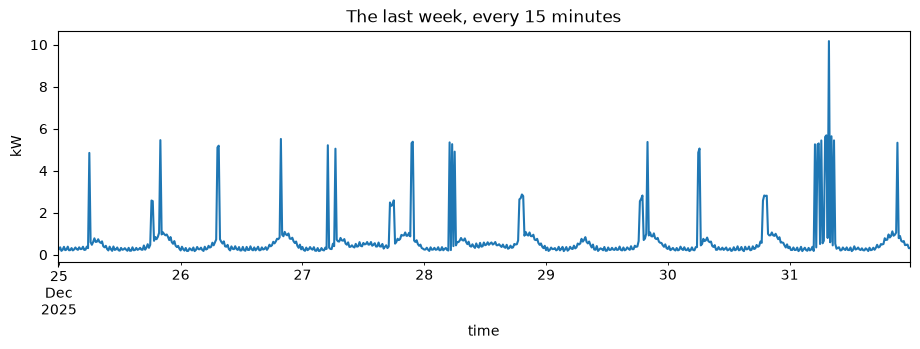

Line chart of the last week of 15-minute power readings. It sits near 0.20 kW for long stretches and spikes to as much as 10.2 kW; the average is 0.68 kW.


In [4]:
week = kw[kw.index >= kw.index.max() - pd.Timedelta(days=7)]
week.plot(figsize=(11, 3), ylabel='kW', title='The last week, every 15 minutes')
ALT_TEXT = (f'Line chart of the last week of 15-minute power readings. It sits '
            f'near {week.quantile(0.05):.2f} kW for long stretches and spikes to '
            f'as much as {week.max():.1f} kW; the average is {week.mean():.2f} kW.')
plt.show()
print(ALT_TEXT)


> Look at the lowest points, around 3 a.m. What is this house drawing when nobody is doing anything, and what is always on?


## Part B - The shape


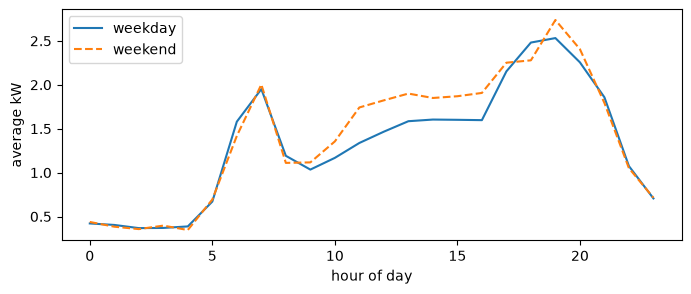

Two lines of average power by hour of day. Weekdays (solid) peak at 2.53 kW at hour 19; weekends (dashed) peak at 2.74 kW at hour 19. Both are lowest overnight, near 0.35 kW.


In [5]:
hourly = kw.groupby([kw.index.day_of_week >= 5, kw.index.hour]).mean().unstack(0)
hourly.columns = ['weekday', 'weekend']
ax = hourly.plot(figsize=(8, 3), xlabel='hour of day', ylabel='average kW',
                 style=['-', '--'])         # line style as well as colour
ALT_TEXT = (f'Two lines of average power by hour of day. Weekdays (solid) peak at '
            f'{hourly.weekday.max():.2f} kW at hour {hourly.weekday.idxmax()}; '
            f'weekends (dashed) peak at {hourly.weekend.max():.2f} kW at hour '
            f'{hourly.weekend.idxmax()}. Both are lowest overnight, near '
            f'{hourly.min().min():.2f} kW.')
plt.show()
print(ALT_TEXT)


The same by month as well as by hour: each cell of the map is the average kW in that hour of that month.


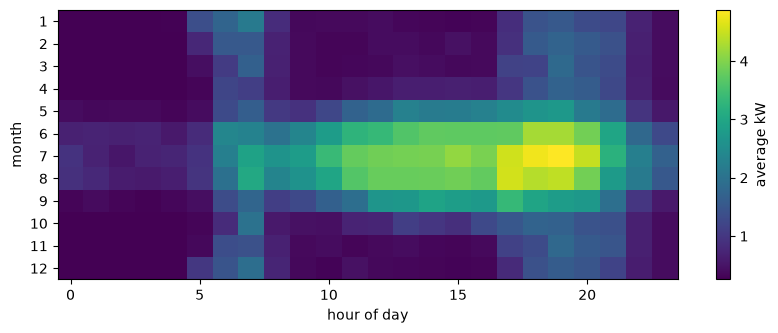

Heat map of average power, months down the side and hours of the day across. The brightest cell is month 7 at hour 19, 4.87 kW; the darkest is 0.26 kW.


In [6]:
grid = kw.groupby([kw.index.month, kw.index.hour]).mean().unstack()
plt.figure(figsize=(10, 3.5))
plt.imshow(grid, aspect='auto', cmap='viridis')
plt.colorbar(label='average kW')
plt.yticks(range(len(grid)), grid.index)
plt.xlabel('hour of day'); plt.ylabel('month')
month, hour = grid.stack().idxmax()
ALT_TEXT = (f'Heat map of average power, months down the side and hours of the '
            f'day across. The brightest cell is month {month} at hour {hour}, '
            f'{grid.loc[month, hour]:.2f} kW; the darkest is '
            f'{grid.min().min():.2f} kW.')
plt.show()
print(ALT_TEXT)


> When is the peak, and does it move between summer and winter? Looking only at this picture, would rooftop solar cut this house's peak - or just its midday?


## Part C - The spikes

A big appliance switching on shows up as a **step**: the load jumps from one 15-minute reading to the next.


In [7]:
steps = kw.diff()
biggest = steps.nlargest(10)
pd.DataFrame({'jump kW': biggest.round(2),
              'time of day': biggest.index.strftime('%a %H:%M'),
              'month': biggest.index.strftime('%b')})


,jump kW,time of day,month
time,,,
2025-01-15 06:00:00,9.72,Wed 06:00,Jan
2025-01-09 07:00:00,9.66,Thu 07:00,Jan
2025-01-02 07:45:00,9.55,Thu 07:45,Jan
2025-12-31 07:45:00,9.38,Wed 07:45,Dec
2025-02-10 07:30:00,9.38,Mon 07:30,Feb
2025-06-23 06:15:00,8.35,Mon 06:15,Jun
2025-07-02 06:45:00,8.33,Wed 06:45,Jul
2025-06-24 06:45:00,8.31,Tue 06:45,Jun
2025-08-15 07:30:00,8.30,Fri 07:30,Aug


> Pick three of these steps. What appliance could each one be? Then the harder question: what in the data would tell a dryer from a water heater from an air conditioner? Several answers usually fit - say which evidence decides it.


---
### Does the package agree?

`esm.meter` reads the same export a different way - numpy reshapes over whole days instead of pandas `groupby` and `diff` - and has to land on the same numbers. The ten largest steps are compared as **sizes**: two equal jumps can sort either way round, so which timestamp came first is not a result.


In [8]:
import numpy as np
from esm.meter import biggest_steps, hourly_profile, to_kw
from esm.tolerance import AGREEMENT_RTOL, relative

pkg_kw, pkg_export = to_kw(raw)
pkg_hourly = hourly_profile(pkg_kw)
checks = [('readings', len(kw), len(pkg_kw)),
          ('kWh used', use.sum(), pkg_kw.sum() / 4),
          ('kWh exported', export.sum(), pkg_export)]
checks += [(f'{d} hour {h}', hourly.at[h, d], pkg_hourly.at[h, d])
           for d in ('weekday', 'weekend') for h in range(24)]
checks += [(f'step {i + 1}', a, b)
           for i, (a, b) in enumerate(zip(biggest.to_numpy(), biggest_steps(pkg_kw)))]

worst = max(relative(a, b) for _, a, b in checks)
print(f'{len(checks)} quantities compared; largest relative difference {worst:.1e}')
assert worst < AGREEMENT_RTOL, f'notebook and package disagree by {worst:.2e}'
print(f'notebook and package agree to {worst:.1e}')


61 quantities compared; largest relative difference 4.9e-15
notebook and package agree to 4.9e-15


*Before class: one house's peak is a few kW. If you were sizing the service for a 200-home subdivision, would you add up 200 of these peaks - and if not, why not?*

### Sources
- Smart Meter Texas interval export (15-minute kWh; consumption and surplus generation rows).
- The invented house: `esm.meter.synthetic_export`, built from typical appliance nameplates. It is not a measurement of any real home.
